# Figure 3 Supplement 1: Stopping-model fit quality

Does the fitted stopping model reproduce the data it was fit to? Each subject
is simulated `SIM_REPS` times over their own trials (same block, step
statistics and trial count) from their main fit, and the simulated data are
compared with the real data.

OL low-SNR blocks 1–3 (no-penalty, coin-penalty and step-penalty conditions),
as in the other Figure 3 supplements.

- **A — RT distributions**, pooled over subjects; the last bin (15+) collects
  RT ≥ 15.
- **B — accuracy vs. RT** (RT bins with ≥ 20 trials). RT = 1 responses (key
  pressed on the first frame) are anticipations with a random choice in the
  model.

**Data:** `get_stopping_model_trials('OL', 1–6)` (the trials the model was fit
to; fits are joint over a subject's six blocks), blocks 1–3 shown. Fits: `data/processed/stopping_fits_main.pkl`. All subject-blocks are
included, also those whose plateau sits at a fit limit
(`get_plateau_at_limit`): the model still describes their behavior (random
responding, or committing on any movement), so they belong in a test of fit
quality; their count is printed.

**Conventions:** black = data, blue = model. Replaces the old Figure03S01
(congruence by RT; archived in `notebooks/archive/`).

In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import scipy.stats

from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label
from pigeon.stopping import get_plateau_at_limit, get_stopping_model_trials, simulate_stopping_data_table

PROCESSED = Path('../data/processed')

In [2]:
SIM_REPS = 5
SIM_SEED = 11
BLOCKS = ['B1', 'B2', 'B3']   # OL low-SNR blocks, as in the other Figure 3 supplements
BLOCK_TITLES = {'B1': 'No penalty', 'B2': 'Coin penalty', 'B3': 'Step penalty'}

# Fit and simulate on all six blocks (the fits are joint across a subject's blocks); show 1-3.
trials = get_stopping_model_trials('OL', [1, 2, 3, 4, 5, 6])
fits_all = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl')
fits_all = fits_all[fits_all.task == 'OL']
fits = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl')
fits = fits[(fits.task == 'OL') & fits.group.isin(BLOCKS)]
trials = trials[trials.condition.isin(BLOCKS)]
sim = simulate_stopping_data_table(trials, fits_all, group_col='condition', num_reps=SIM_REPS,
                                   rng=np.random.default_rng(SIM_SEED))
l_limit = get_plateau_at_limit(fits)
print(f'{len(trials):,} real trials, {len(sim):,} simulated; {fits.subject_index.nunique()} subjects, '
      f'{len(fits)} subject-blocks ({int(l_limit.sum())} with the plateau at a fit limit, included)')

OL: subjects with a good adaptation tau fit, by block: {1: 2, 2: 25, 3: 9, 4: 18, 5: 8, 6: 9}
OL: 42,252 trials in blocks [1, 2, 3, 4, 5, 6]; excluded 3,240 with trial_number < 10, 225 more in the adaptation transient, 364 more with no choice; 60 subjects


14,056 real trials, 70,280 simulated; 60 subjects, 179 subject-blocks (5 with the plateau at a fit limit, included)


In [3]:
MAX_RT = 15
MIN_ACC_TRIALS = 20
rt_ax = np.arange(1, MAX_RT + 1)

def _rt_dist(t):
    return t.RT.clip(upper=MAX_RT).value_counts(normalize=True).reindex(rt_ax, fill_value=0.0)

def _acc_by_rt(t):
    a = t.groupby(t.RT.clip(upper=MAX_RT)).correct.agg(['mean', 'size']).reindex(rt_ax)
    return a['mean'].where(a['size'] >= MIN_ACC_TRIALS * (SIM_REPS if 'rep' in t else 1))

# Largest RT-distribution mismatches, for the record.
mis = pd.DataFrame({b: _rt_dist(sim[sim.condition == b]) - _rt_dist(trials[trials.condition == b]) for b in BLOCKS})
print('model − data P(RT), largest absolute differences:')
print(mis.stack().abs().sort_values(ascending=False).head(6).round(3))

model − data P(RT), largest absolute differences:
RT    
3   B1    0.030
    B3    0.018
2   B1    0.016
3   B2    0.015
6   B3    0.012
    B1    0.010
dtype: float64


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


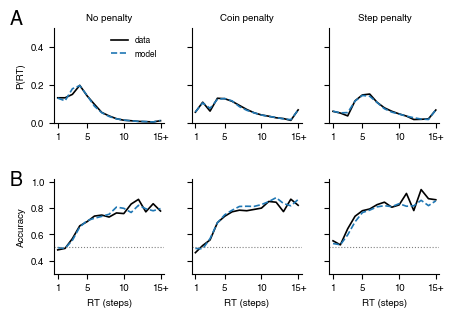

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S01.pdf (+ .png)


In [4]:
CM = 1 / 2.54
FS = 7
plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})
MODEL = 'tab:blue'

fig = plt.figure(figsize=(11 * CM, 8 * CM))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.6, wspace=0.25, left=0.1, right=0.99, bottom=0.12, top=0.9)
ax_rt = [fig.add_subplot(gs[0, i]) for i in range(3)]
ax_acc = [fig.add_subplot(gs[1, i]) for i in range(3)]

for bi, b in enumerate(BLOCKS):
    r, s = trials[trials.condition == b], sim[sim.condition == b]
    ax = ax_rt[bi]
    ax.plot(rt_ax, _rt_dist(r), 'k-', lw=1.2, label='data')
    ax.plot(rt_ax, _rt_dist(s), '--', color=MODEL, lw=1.2, label='model')
    ax.set_title(BLOCK_TITLES[b])
    ax.set_ylim(0, 0.5)
    ax = ax_acc[bi]
    ax.plot(rt_ax, _acc_by_rt(r), 'k-', lw=1.2)
    ax.plot(rt_ax, _acc_by_rt(s), '--', color=MODEL, lw=1.2)
    ax.axhline(0.5, color='0.5', ls=':', lw=0.8)
    ax.set_ylim(0.3, 1.02)
    ax.set_xlabel('RT (steps)')
    for a in (ax_rt[bi], ax_acc[bi]):
        a.set_xlim(0.5, MAX_RT + 0.5)
        a.set_xticks([1, 5, 10, 15])
        a.set_xticklabels(['1', '5', '10', '15+'])  # last bin: RT >= 15
        if bi > 0:
            a.set_yticklabels([])
ax_rt[0].set_ylabel('P(RT)')
ax_acc[0].set_ylabel('Accuracy')
ax_rt[0].legend(fontsize=6, frameon=False, loc='upper right')

for ax in ax_rt + ax_acc:
    ax.spines[['top', 'right']].set_visible(False)
add_panel_label(ax_rt[0], 'A', dx=-0.4, dy=1.2)
add_panel_label(ax_acc[0], 'B', dx=-0.4, dy=1.1)

out = FIGURES_DIR / 'Figure03_S01.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')

## Interpretation

(Filled in after review.)